# 电商用户行为分析 v2
数据：Retailrocket（Kaggle，CC BY-NC-SA 4.0），2015-05 ~ 2015-09 行为日志。

In [ ]:
import pandas as pd, numpy as np, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK SC", "WenQuanYi Zen Hei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120

df = pd.read_csv("data/events.csv")
raw = len(df)
df = df.drop_duplicates()
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")
df["date"] = df["datetime"].dt.date
df["hour"] = df["datetime"].dt.hour
print(f"原始行数 {raw:,}，去重后 {len(df):,}（删除 {raw-len(df):,} 条重复）")
print(f"时间范围 {df.datetime.min():%Y-%m-%d} ~ {df.datetime.max():%Y-%m-%d}")
print(f"访客 {df.visitorid.nunique():,}，商品 {df.itemid.nunique():,}")
print(df.event.value_counts().rename("事件数").to_string())

原始行数 2,756,101，去重后 2,755,641（删除 460 条重复）
时间范围 2015-05-03 ~ 2015-09-18
访客 1,407,580，商品 235,061
event
view           2664218
addtocart        68966
transaction      22457


## 一、转化漏斗：事件级 vs 用户级
事件级容易被误读，用户级才代表“多少人走到了下一步”。

事件级漏斗：
        事件级   环节转化率  整体转化率
浏览  2664218       -      -
加购    68966   2.59%  2.59%
成交    22457  32.56%  0.84%

用户级漏斗：
          人数   环节转化率   占全部访客
浏览过  1404179       -  99.76%
加购过    37722   2.69%   2.68%
成交过    11719  31.07%   0.83%


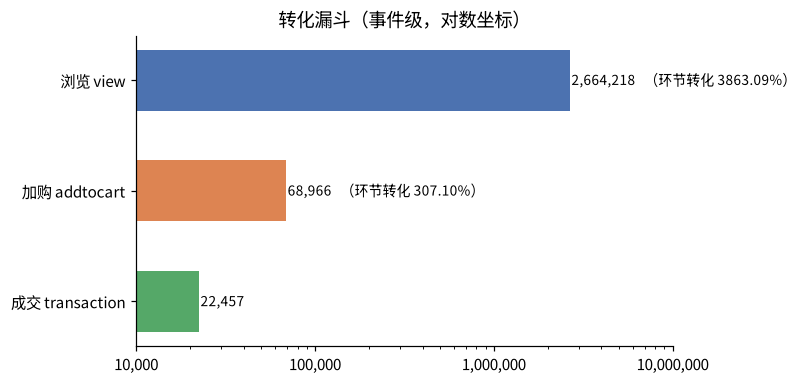

In [ ]:
vc = df.event.value_counts()
view, cart, buy = vc["view"], vc["addtocart"], vc["transaction"]
ev_funnel = pd.DataFrame({
    "事件级": [view, cart, buy],
    "环节转化率": ["-", f"{cart/view:.2%}", f"{buy/cart:.2%}"],
}, index=["浏览", "加购", "成交"]).assign(整体转化率=["-", f"{cart/view:.2%}", f"{buy/view:.2%}"])

users = df.groupby("event").visitorid.nunique()
uv, uc, ub = users["view"], users["addtocart"], users["transaction"]
user_funnel = pd.DataFrame({
    "人数": [uv, uc, ub],
    "环节转化率": ["-", f"{uc/uv:.2%}", f"{ub/uc:.2%}"],
    "占全部访客": [f"{uv/df.visitorid.nunique():.2%}", f"{uc/df.visitorid.nunique():.2%}", f"{ub/df.visitorid.nunique():.2%}"],
}, index=["浏览过", "加购过", "成交过"])
print("事件级漏斗："); print(ev_funnel.to_string())
print("\n用户级漏斗："); print(user_funnel.to_string())

fig, ax = plt.subplots(figsize=(7.2, 3.6))
stages = ["浏览 view", "加购 addtocart", "成交 transaction"]
vals = [view, cart, buy]
colors = ["#4c72b0", "#dd8452", "#55a868"]
bars = ax.barh(stages[::-1], vals[::-1], color=colors[::-1], height=0.55)
for b, v, prev in zip(bars, vals[::-1], [None, buy, cart]):
    label = f"{v:,}"
    if prev: label += f"   （环节转化 {v/prev:.2%}）"
    ax.text(b.get_width()*1.02, b.get_y()+b.get_height()/2, label, va="center", fontsize=9)
ax.set_xscale("log"); ax.set_xlim(1e4, 1e7)
ax.set_title("转化漏斗（事件级，对数坐标）")
ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout(); plt.savefig("figs/funnel.png", bbox_inches="tight"); plt.close(fig)

## 二、时间趋势：DAU 与成交

DAU 均值 11,867，最高 17,516（2015-07-26），最低 1,016
日均成交 162 笔，成交高峰 2015-06-16（276 笔）


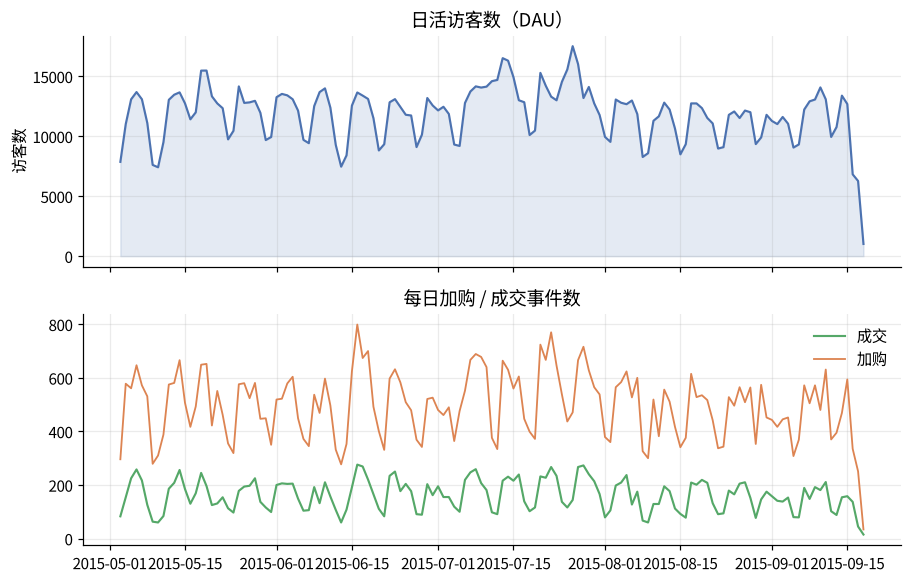

In [ ]:
daily = df.groupby(["date", "event"]).size().unstack(fill_value=0)
dau = df.groupby("date").visitorid.nunique()
fig, axes = plt.subplots(2, 1, figsize=(8.4, 5.4), sharex=True)
axes[0].plot(dau.index, dau.values, color="#4c72b0", lw=1.4)
axes[0].fill_between(dau.index, dau.values, alpha=0.15, color="#4c72b0")
axes[0].set_title("日活访客数（DAU）"); axes[0].set_ylabel("访客数")
axes[1].plot(daily.index, daily["transaction"], color="#55a868", lw=1.4, label="成交")
axes[1].plot(daily.index, daily["addtocart"], color="#dd8452", lw=1.2, label="加购")
axes[1].set_title("每日加购 / 成交事件数"); axes[1].legend(frameon=False)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig("figs/trend.png", bbox_inches="tight"); plt.close(fig)
print(f"DAU 均值 {dau.mean():,.0f}，最高 {dau.max():,}（{dau.idxmax()}），最低 {dau.min():,}")
print(f"日均成交 {daily['transaction'].mean():,.0f} 笔，成交高峰 {daily['transaction'].idxmax()}（{daily['transaction'].max():,} 笔）")

## 三、RFM 分层（仅成交用户）
数据无金额字段，M 维度缺失，用 R、F 两维。

成交用户 11,719 人
segment
高价值     25.4%
流失      25.3%
潜力      24.7%
重要保持    24.6%


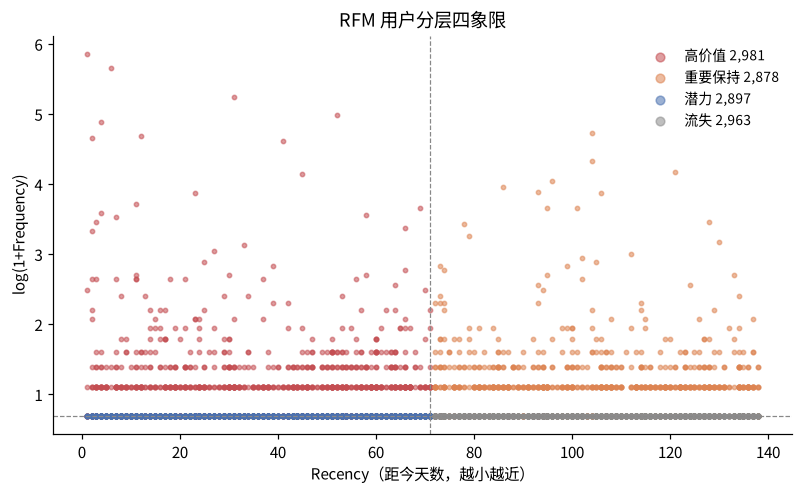

In [ ]:
t = df[df.event == "transaction"].copy()
snapshot = df.datetime.max() + pd.Timedelta(days=1)
rfm = t.groupby("visitorid").agg(last=("datetime", "max"), frequency=("event", "size"))
rfm["recency"] = (snapshot - rfm["last"]).dt.days
rfm["R"] = pd.qcut(rfm.recency, 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm.frequency.rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)

def seg(r):
    if r.R >= 3 and r.F >= 3: return "高价值"
    if r.R >= 3 and r.F < 3: return "潜力"
    if r.R < 3 and r.F >= 3: return "重要保持"
    return "流失"
rfm["segment"] = rfm.apply(seg, axis=1)
seg_counts = rfm.segment.value_counts()
print(f"成交用户 {len(rfm):,} 人")
print((seg_counts / len(rfm)).map(lambda x: f"{x:.1%}").to_string())

fig, ax = plt.subplots(figsize=(7.4, 4.6))
palette = {"高价值": "#c44e52", "重要保持": "#dd8452", "潜力": "#4c72b0", "流失": "#8c8c8c"}
s = rfm.sample(min(len(rfm), 6000), random_state=0)
for k, c in palette.items():
    d = s[s.segment == k]
    ax.scatter(d.recency, np.log1p(d.frequency), s=8, alpha=0.55, color=c, label=f"{k} {seg_counts.get(k,0):,}")
ax.axvline(rfm.recency.median(), ls="--", lw=0.8, c="#888")
ax.axhline(np.log1p(rfm.frequency.median()), ls="--", lw=0.8, c="#888")
ax.set_xlabel("Recency（距今天数，越小越近）"); ax.set_ylabel("log(1+Frequency)")
ax.set_title("RFM 用户分层四象限")
ax.legend(frameon=False, fontsize=9, markerscale=2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figs/rfm.png", bbox_inches="tight"); plt.close(fig)

## 四、K-Means 修正版
频率长尾严重 → 先 `log1p` 再标准化；用轮廓系数和肘部法选 k，而不是拍脑袋 k=4。

k=2  silhouette=0.4663
k=3  silhouette=0.5076
k=4  silhouette=0.5174
k=5  silhouette=0.4623
k=6  silhouette=0.4931
k=7  silhouette=0.5284
k=8  silhouette=0.5217
轮廓系数最优 k=7
           人数    平均R   平均F     占比
cluster                          
4          74   62.4  75.3   0.6%
5         284   58.0   8.4   2.4%
1        1056  106.4   2.4   9.0%
2        1162   38.6   2.4   9.9%
0        3367   71.8   1.0  28.7%
3        2893   25.0   1.0  24.7%
6        2883  117.3   1.0  24.6%


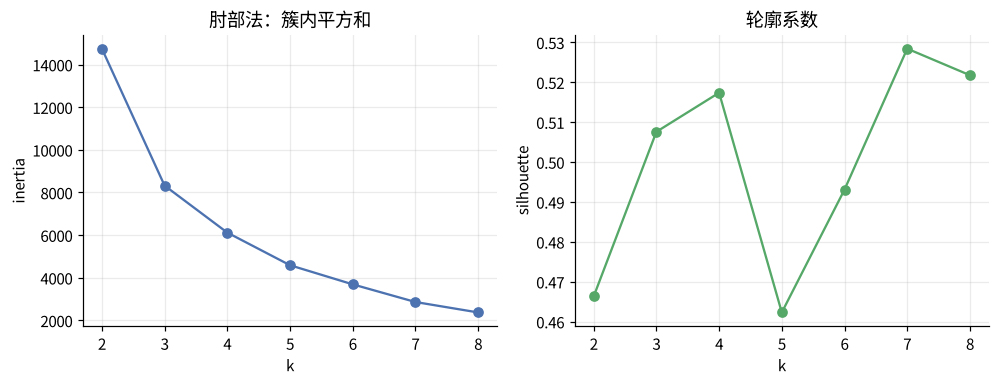

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = rfm[["recency", "frequency"]].copy()
X["frequency"] = np.log1p(X.frequency)
X = StandardScaler().fit_transform(X)

ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_, sample_size=5000, random_state=0))
for k, s_ in zip(ks, sil): print(f"k={k}  silhouette={s_:.4f}")
best_k = ks[int(np.argmax(sil))]
print(f"轮廓系数最优 k={best_k}")

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.6))
axes[0].plot(list(ks), inertia, "o-", color="#4c72b0"); axes[0].set_title("肘部法：簇内平方和")
axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia")
axes[1].plot(list(ks), sil, "o-", color="#55a868"); axes[1].set_title("轮廓系数")
axes[1].set_xlabel("k"); axes[1].set_ylabel("silhouette")
for ax in axes: ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig("figs/kmeans_eval.png", bbox_inches="tight"); plt.close(fig)

km = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(X)
rfm["cluster"] = km.labels_
prof = rfm.groupby("cluster").agg(人数=("cluster", "size"), 平均R=("recency", "mean"), 平均F=("frequency", "mean")).round(1)
prof["占比"] = (prof.人数 / len(rfm)).map(lambda x: f"{x:.1%}")
prof = prof.sort_values("平均F", ascending=False)
print(prof.to_string())

## 五、结论
- 漏斗瓶颈：浏览→加购环节转化率仅 2.59%（事件级）/ 见用户级口径
- 成交集中在极少数用户：高价值用户贡献主要订单
- 频率长尾使聚类失衡，log 变换后分层更稳定

In [ ]:
print("高价值用户占比", f"{(seg_counts['高价值']/len(rfm)):.1%}")
print("成交用户人均订单", f"{rfm.frequency.mean():.2f}")
print("成交用户中只买过 1 次的比例", f"{(rfm.frequency==1).mean():.1%}")

高价值用户占比 25.4%
成交用户人均订单 1.92
成交用户中只买过 1 次的比例 78.0%


## 六、成交集中度：是不是“少数人贡献多数订单”

 用户占比  订单占比
 前 1% 27.8%
 前 5% 39.6%
前 10% 46.8%
前 20% 57.2%
只买过 1 次：78.0%；人均订单 1.92


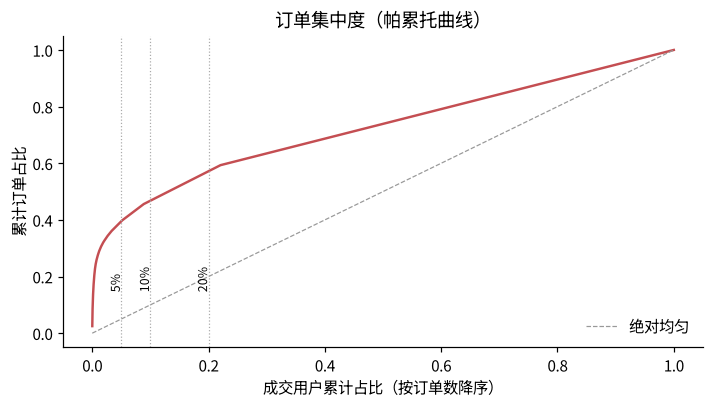

In [ ]:
freq_sorted = rfm.frequency.sort_values(ascending=False)
total_orders = freq_sorted.sum()
rows = []
for p in [0.01, 0.05, 0.10, 0.20]:
    n = max(1, int(len(freq_sorted) * p))
    rows.append({"用户占比": f"前 {p:.0%}", "订单占比": f"{freq_sorted.iloc[:n].sum()/total_orders:.1%}"})
print(pd.DataFrame(rows).to_string(index=False))
print(f"只买过 1 次：{(rfm.frequency==1).mean():.1%}；人均订单 {rfm.frequency.mean():.2f}")

fig, ax = plt.subplots(figsize=(6.6, 3.8))
cum = freq_sorted.cumsum() / total_orders
x = np.arange(1, len(cum) + 1) / len(cum)
ax.plot(x, cum.values, color="#c44e52", lw=1.6)
ax.plot([0, 1], [0, 1], ls="--", lw=0.8, c="#999", label="绝对均匀")
for p in [0.05, 0.10, 0.20]:
    ax.axvline(p, ls=":", lw=0.8, c="#aaa")
    ax.text(p, 0.15, f"{p:.0%}", rotation=90, fontsize=8, ha="right")
ax.set_xlabel("成交用户累计占比（按订单数降序）"); ax.set_ylabel("累计订单占比")
ax.set_title("订单集中度（帕累托曲线）"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figs/pareto.png", bbox_inches="tight"); plt.close(fig)